# 05 — Feature Extraction and Feature Selection
**Day 5 · Phase 3: Feature Extraction and Selection**

### Two different ideas
- **Feature extraction** *creates new features* by transforming existing information. Day 4 already did this from
  text (processor → tier/vendor; model name → brand/5G/premium flags). **PCA** is the classic numeric example: it
  builds new axes (principal components) as combinations of the originals.
- **Feature selection** *keeps a subset of existing features* and drops the rest (correlation filters, variance
  threshold, statistical tests, SelectKBest, RFE).

### The techniques and their intuition
| Technique | Type | Intuition |
|---|---|---|
| **Pearson r** | filter (selection) | Strength of a *straight-line* relationship: r = cov(x, y) / (σₓσᵧ), in [−1, 1]. Sensitive to outliers. |
| **Spearman ρ** | filter | Pearson computed on *ranks*: captures any monotonic relationship (“more → more”), robust to skew. |
| **Mutual information** | filter | How much knowing x reduces uncertainty about y: I(X;Y) = Σ p(x,y) log p(x,y)/(p(x)p(y)). 0 = independent; captures non-monotonic relationships too. Estimated with k-nearest neighbours, so it's noisy → averaged over seeds. |
| **Variance threshold** | filter | Drops near-constant features — a column that almost never changes can't explain much. Ignores the target. |
| **F-test (f_regression)** | statistical filter | For each feature, tests H₀: “no linear relationship with y” via F = r²/(1−r²)·(n−2); gives a p-value. |
| **SelectKBest** | filter wrapper | Keeps the k highest-scoring features under a score (F or MI); k is tuned by cross-validation. |
| **RFE** | wrapper | Fit a model, drop the least important feature, repeat; ranks features by elimination order. Uses a model, so it accounts for other features (unlike filters). |
| **PCA** | extraction | Rotates standardised features onto orthogonal directions of maximum variance. Keeping the first k components compresses the data, losing the variance in the discarded ones. It ignores the target. |

All analysis below uses **training data only** (419 rows). Any selection step evaluated by cross-validation sits
*inside* the pipeline, so it is re-fitted in each fold and never sees validation data.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.plot_style import (apply_style, save_fig, rupee_axis, PALETTE, PRIMARY, ACCENT,
                            NEUTRAL, DIVERGING, SEQUENTIAL)

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
RANDOM_STATE = 42

from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import (RFE, RFECV, SelectKBest, VarianceThreshold, f_regression,
                                       mutual_info_regression)
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from src.train import load_model_ready_data, xy, group_cv
from src.feature_engineering import make_preprocessor, NUMERIC_FEATURES
from src.feature_selection import correlation_with_target, mutual_information
from src.evaluate import cv_summary

train, test = load_model_ready_data()
X_tr, y_tr, g_tr = xy(train)
log_y = np.log(y_tr)

prep = make_preprocessor()                  # fitted on training data only
X_enc = prep.fit_transform(X_tr)
print("Encoded training features:", X_enc.shape)

Encoded training features: (419, 29)


## 1. Pearson and Spearman correlation

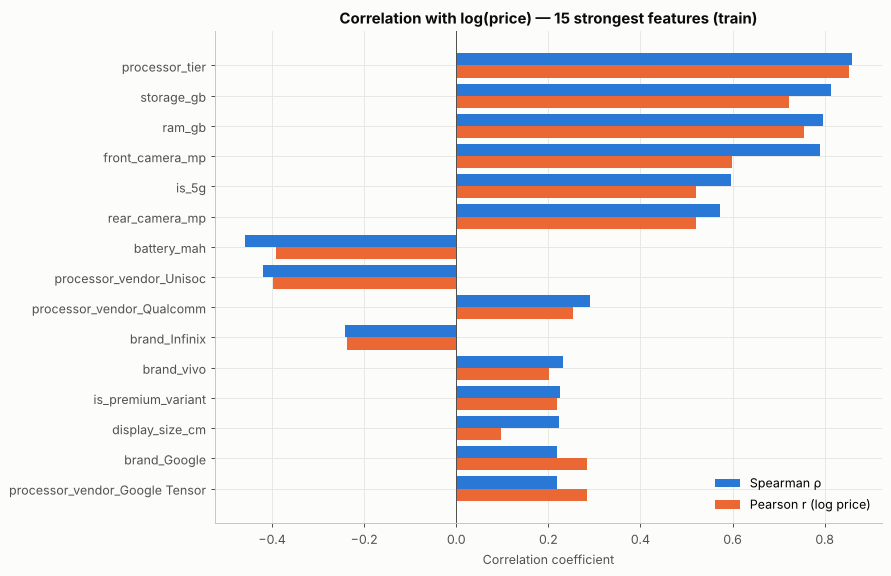

,pearson,spearman,pearson_raw_price
feature,,,
processor_tier,0.852,0.859,0.807
storage_gb,0.722,0.814,0.588
ram_gb,0.755,0.796,0.588
front_camera_mp,0.598,0.789,0.492
is_5g,0.520,0.597,0.349
rear_camera_mp,0.520,0.573,0.373
battery_mah,-0.391,-0.458,-0.448
processor_vendor_Unisoc,-0.399,-0.421,-0.300
processor_vendor_Qualcomm,0.253,0.290,0.158


In [2]:
corr = correlation_with_target(X_enc, log_y)
corr["pearson_raw_price"] = [X_enc[c].corr(y_tr) for c in corr.index]
top = corr.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
yy = np.arange(len(top))
ax.barh(yy + 0.2, top["spearman"], height=0.4, color=PRIMARY, label="Spearman ρ")
ax.barh(yy - 0.2, top["pearson"], height=0.4, color=ACCENT, label="Pearson r (log price)")
ax.set_yticks(yy, top.index); ax.axvline(0, color="#52514e", lw=0.8)
ax.set(title="Correlation with log(price) — 15 strongest features (train)", xlabel="Correlation coefficient")
ax.legend(loc="lower right"); fig.tight_layout(); save_fig(fig, "fs_correlation_ranking")
corr[["pearson", "spearman", "pearson_raw_price"]].head(15)

**Interpretation.** Processor tier, storage, front camera, RAM and the 5G flag lead on both measures. Against
**log** price, Pearson and Spearman agree closely, confirming that the log transform makes most relationships
roughly linear (Pearson against *raw* price is weaker for every top feature). Battery is the strongest *negative*
feature. Infinix and Unisoc are negative (budget brand/chip vendor); Qualcomm and Google are positive.

## 2. Mutual information

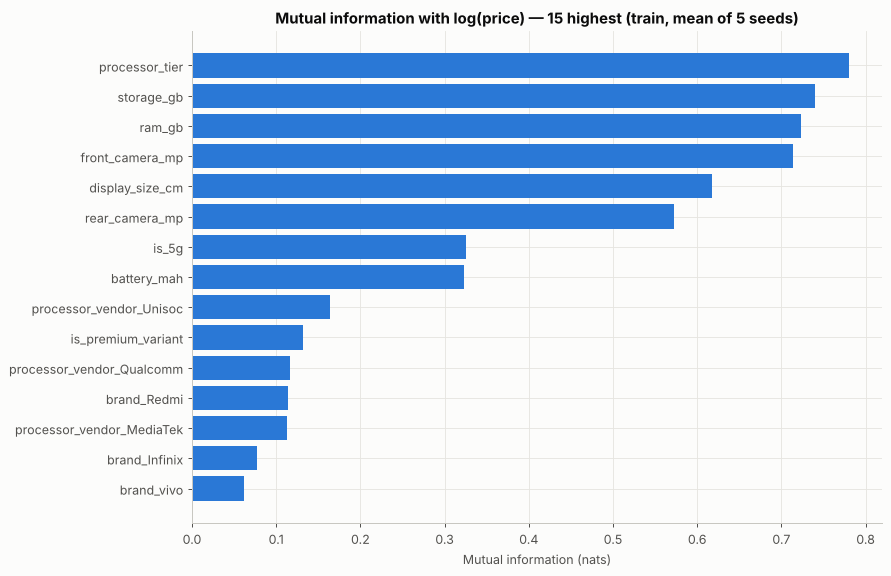

,processor_tier,storage_gb,ram_gb,front_camera_mp,display_size_cm,rear_camera_mp,is_5g,battery_mah,processor_vendor_Unisoc,is_premium_variant,processor_vendor_Qualcomm,brand_Redmi,processor_vendor_MediaTek,brand_Infinix,brand_vivo,ai_lens,brand_Tecno,brand_realme,brand_Google,processor_vendor_Google Tensor,processor_vendor_Samsung Exynos,brand_infrequent_sklearn,brand_Apple,processor_vendor_Apple,brand_Motorola,brand_OPPO,brand_Samsung,processor_vendor_Unknown,brand_POCO
MI,0.780,0.740,0.723,0.714,0.618,0.573,0.326,0.324,0.164,0.132,0.117,0.115,0.113,0.077,0.062,0.052,0.051,0.049,0.048,0.048,0.046,0.045,0.042,0.042,0.029,0.023,0.015,0.005,0.005


In [3]:
discrete = np.array([X_enc[c].nunique() <= 10 for c in X_enc.columns])
mi = mutual_information(X_enc, log_y, discrete_mask=discrete, n_repeats=5)
fig, ax = plt.subplots(figsize=(10, 6.5))
top_mi = mi.head(15).iloc[::-1]
ax.barh(top_mi.index, top_mi.values, color=PRIMARY)
ax.set(title="Mutual information with log(price) — 15 highest (train, mean of 5 seeds)", xlabel="Mutual information (nats)")
fig.tight_layout(); save_fig(fig, "fs_mutual_information")
mi.round(3).to_frame("MI").T

**Interpretation.** MI agrees with correlation on the core: processor tier, storage, RAM and front camera carry
the most information (≈ 0.71–0.78 nats). One clear disagreement: **display size** has high MI (0.62) but almost no
correlation (ρ = 0.22). Exact display sizes (16.76, 16.94, 17.02 cm …) are shared by specific models and brands, so
they work like a *fingerprint* of the phone family rather than a reason for its price. MI rewards that; it's a warning
that display size could help a model memorise families rather than generalise. Brand dummies score low individually
because each covers few rows, even though brand as a whole matters.

## 3. Variance threshold

In [4]:
var = X_enc.var().sort_values()
binary = [c for c in X_enc.columns if X_enc[c].nunique() <= 2]
vt = VarianceThreshold(threshold=0.01).fit(X_enc[binary])
dropped = [c for c, keep in zip(binary, vt.get_support()) if not keep]
print("Binary features with variance < 0.01 (present in < ~1% of rows):", dropped)
print("\nLowest-variance binary features:")
X_enc[binary].var().sort_values().head(6).round(4).to_dict()

Binary features with variance < 0.01 (present in < ~1% of rows): []

Lowest-variance binary features:


{'brand_Apple': 0.0118, 'processor_vendor_Apple': 0.0118, 'brand_Google': 0.0188, 'processor_vendor_Google Tensor': 0.0188, 'processor_vendor_Unknown': 0.0211, 'brand_Tecno': 0.0301}

**Interpretation.** Variance threshold is only meaningful on comparable scales, so it's applied to the 0/1
features (variance = p(1−p)). With rare brands already pooled by `min_frequency=5`, **no column falls below 0.01**;
the rarest are `brand_Apple`/`processor_vendor_Apple` (0.0118, five rows). Low variance ≠ useless: `brand_Apple` is rare but
explains the most expensive phones. This filter is a sanity check, not a selection criterion here.

## 4. Statistical test (F-test) and SelectKBest

In [5]:
F, p = f_regression(X_enc, log_y)
stat = pd.DataFrame({"F": F, "p_value": p}, index=X_enc.columns).sort_values("F", ascending=False)
stat["significant (p<0.05)"] = stat["p_value"] < 0.05
print("Features significant at 5%:", int(stat["significant (p<0.05)"].sum()), "of", len(stat))
stat.head(12)

Features significant at 5%: 22 of 29


,F,p_value,significant (p<0.05)
processor_tier,"1,105.223",0.000,True
ram_gb,551.495,0.000,True
storage_gb,453.458,0.000,True
front_camera_mp,232.210,0.000,True
is_5g,154.690,0.000,True
rear_camera_mp,154.649,0.000,True
processor_vendor_Unisoc,78.809,0.000,True
battery_mah,75.287,0.000,True
brand_Apple,43.532,0.000,True
processor_vendor_Apple,43.532,0.000,True


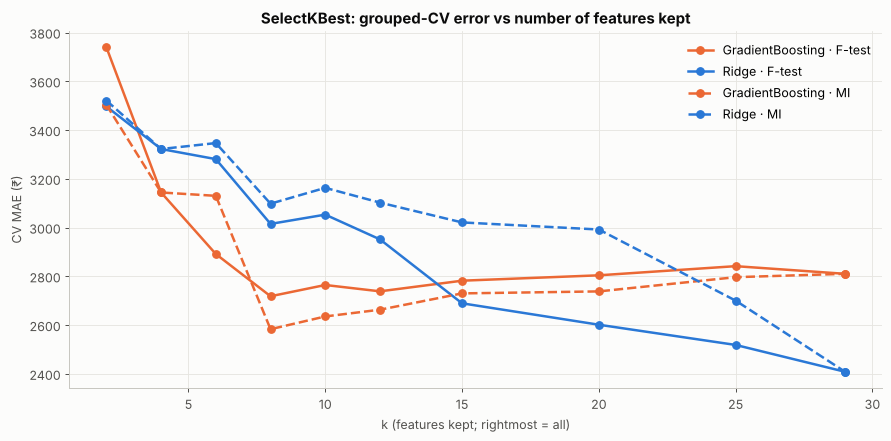

model GradientBoosting               Ridge          
score           F-test        MI    F-test        MI
k_num                                               
2            3,739.000 3,503.000 3,497.000 3,521.000
4            3,144.000 3,144.000 3,322.000 3,322.000
6            2,891.000 3,130.000 3,281.000 3,346.000
8            2,718.000 2,583.000 3,015.000 3,098.000
10           2,764.000 2,635.000 3,053.000 3,163.000
12           2,738.000 2,663.000 2,951.000 3,102.000
15           2,782.000 2,730.000 2,689.000 3,021.000
20           2,804.000 2,738.000 2,601.000 2,992.000
25           2,841.000 2,796.000 2,518.000 2,700.000
29           2,810.000 2,810.000 2,408.000 2,408.000

In [6]:
def selection_pipe(selector, model, scale):
    steps = [("prep", make_preprocessor(scale_numeric=scale))]
    if selector is not None:
        steps.append(("select", selector))
    steps.append(("model", model))
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log1p, inverse_func=np.expm1, check_inverse=False)

ks = [2, 4, 6, 8, 10, 12, 15, 20, 25, "all"]
rows = []
for k in ks:
    for score_name, score_fn in [("F-test", f_regression),
                                 ("MI", lambda X, y: mutual_info_regression(X, y, random_state=RANDOM_STATE))]:
        for model_name, model, scale in [("Ridge", Ridge(alpha=1.0), True),
                                         ("GradientBoosting", GradientBoostingRegressor(random_state=RANDOM_STATE), False)]:
            res = cv_summary(selection_pipe(SelectKBest(score_fn, k=k), model, scale), X_tr, y_tr, group_cv(), g_tr)
            rows.append({"k": k, "score": score_name, "model": model_name, "cv_MAE": res["cv_MAE"], "cv_R2": res["cv_R2"]})
kbest = pd.DataFrame(rows)
kbest["k_num"] = kbest["k"].replace("all", X_enc.shape[1]).astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
for (score, model), d in kbest.groupby(["score", "model"]):
    color = PRIMARY if model == "Ridge" else ACCENT
    ax.plot(d["k_num"], d["cv_MAE"], marker="o", lw=2, ms=6, color=color, ls="-" if score == "F-test" else "--",
            label=f"{model} · {score}")
ax.set(title="SelectKBest: grouped-CV error vs number of features kept", xlabel="k (features kept; rightmost = all)", ylabel="CV MAE (₹)")
ax.legend(); fig.tight_layout(); save_fig(fig, "fs_selectkbest_curve")
kbest.pivot_table(index="k_num", columns=["model", "score"], values="cv_MAE").round(0)

**Interpretation.** 22 of 29 features are individually significant (p < 0.05), led by processor tier
(F ≈ 1,105). The two models respond to selection differently:
- **Ridge** improves steadily as features are added and is best with **all** of them (₹2,408). Its L2 penalty already
  controls weak features, and brand dummies add genuine level shifts.
- **Default Gradient Boosting** is best with **8 MI-selected features (₹2,583 vs ₹2,810 with all)**. An untuned
  boosted model overfits to rare dummy columns; removing them acts as regularisation. Day 8 checks whether this still
  holds after tuning, since tuning adds its own regularisation (e.g. minimum leaf size).

## 5. Recursive Feature Elimination (RFE)

In [7]:
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_enc), columns=X_enc.columns, index=X_enc.index)
rfe_ridge = RFE(Ridge(alpha=1.0), n_features_to_select=1).fit(X_scaled, log_y)
rfe_rf = RFE(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
             n_features_to_select=1, step=1).fit(X_enc, log_y)
rfe = pd.DataFrame({"RFE rank (Ridge)": rfe_ridge.ranking_, "RFE rank (Random Forest)": rfe_rf.ranking_},
                   index=X_enc.columns).sort_values("RFE rank (Random Forest)")
rfe.head(12)

,RFE rank (Ridge),RFE rank (Random Forest)
ram_gb,2,1
front_camera_mp,3,2
processor_tier,1,3
storage_gb,7,4
battery_mah,11,5
rear_camera_mp,13,6
display_size_cm,10,7
is_5g,5,8
brand_realme,28,9
brand_Apple,8,10


In [8]:
rfecv = RFECV(Ridge(alpha=1.0), step=1, cv=group_cv(), scoring="neg_mean_absolute_error", min_features_to_select=1)
rfecv.fit(X_scaled, log_y, groups=g_tr)
print("RFECV (Ridge, grouped CV, log-scale MAE) — optimal number of features:", rfecv.n_features_)
print("Dropped:", list(X_enc.columns[~rfecv.support_]))

RFECV (Ridge, grouped CV, log-scale MAE) — optimal number of features: 22
Dropped: ['ai_lens', 'is_premium_variant', 'brand_Redmi', 'brand_Tecno', 'brand_realme', 'processor_vendor_Samsung Exynos', 'processor_vendor_Unisoc']


**Interpretation.** RFE with a Random Forest keeps **RAM, front camera, processor tier, storage, battery** longest —
the same core as the filters. Ridge's ranking differs: tier, RAM and front camera lead, but it eliminates storage
earlier (rank 7), because storage is largely explained by the correlated RAM/tier once those are in a linear model,
and it keeps brand dummies such as Apple/Infinix that shift the price level. RFECV with grouped CV keeps **22 of 29**
features (dropping AI lens, the premium-variant flag and a few dummies), which again says aggressive reduction
doesn't help a linear model. (RFECV here scores the log target, so it's used for
the feature count, not for rupee error.)

## 6. Principal Component Analysis (feature extraction)
PCA requires **standardised** inputs: otherwise battery (thousands of mAh) would dominate the variance purely
because of its units.

PC1 explains 14.9%; 90% needs 17 components, 95% needs 20 of 29.


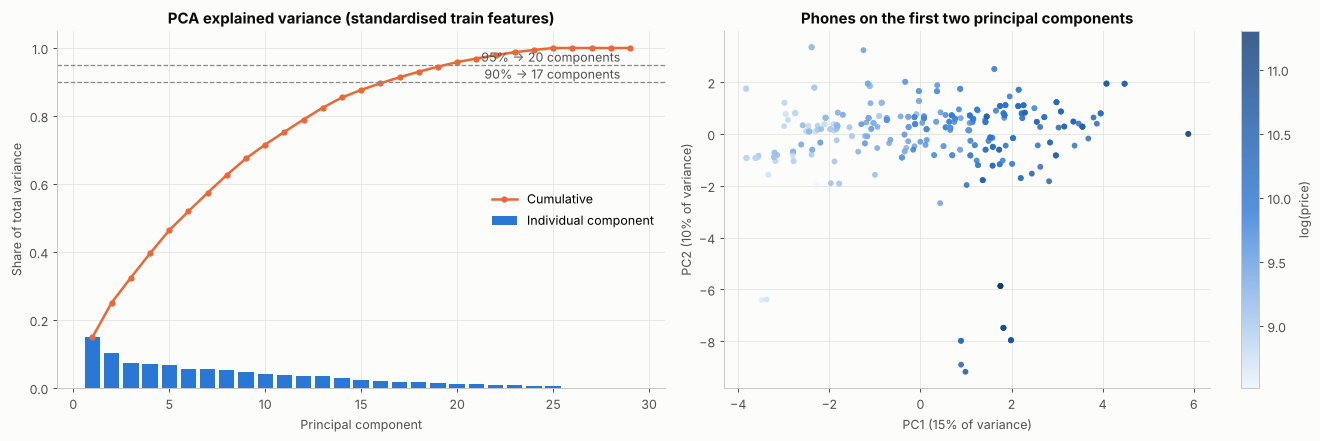

In [9]:
pca = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)
n90, n95 = int(np.searchsorted(cum, 0.90) + 1), int(np.searchsorted(cum, 0.95) + 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
comps = np.arange(1, len(cum) + 1)
axes[0].bar(comps, pca.explained_variance_ratio_, color=PRIMARY, label="Individual component")
axes[0].plot(comps, cum, color=ACCENT, marker="o", ms=4, lw=2, label="Cumulative")
for thr, n in [(0.90, n90), (0.95, n95)]:
    axes[0].axhline(thr, color=NEUTRAL, ls="--", lw=1)
    axes[0].text(len(cum) - 0.5, thr + 0.01, f"{thr:.0%} → {n} components", ha="right", color="#52514e")
axes[0].set(title="PCA explained variance (standardised train features)", xlabel="Principal component",
            ylabel="Share of total variance")
axes[0].legend(loc="center right")

pcs = pca.transform(X_scaled)
sc = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=log_y, cmap=SEQUENTIAL, s=22, alpha=0.8, edgecolor="none")
axes[1].set(title="Phones on the first two principal components", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
cb = fig.colorbar(sc, ax=axes[1]); cb.set_label("log(price)")
fig.tight_layout(); save_fig(fig, "fs_pca_explained_variance")
print(f"PC1 explains {pca.explained_variance_ratio_[0]:.1%}; 90% needs {n90} components, 95% needs {n95} of {len(cum)}.")

In [10]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X_enc.columns, columns=["PC1", "PC2", "PC3"])
loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(10).round(3)

,PC1,PC2,PC3
storage_gb,0.397,0.071,-0.020
ram_gb,0.392,-0.006,-0.035
processor_tier,0.390,-0.162,0.011
front_camera_mp,0.336,0.000,0.017
rear_camera_mp,0.322,0.158,-0.030
is_5g,0.303,0.165,-0.040
processor_vendor_Unisoc,-0.262,-0.100,-0.017
processor_vendor_Qualcomm,0.173,-0.030,-0.061
is_premium_variant,0.160,0.045,0.201
battery_mah,-0.132,0.381,-0.138


In [11]:
pca_rows = []
for n in [2, 3, 5, 8, 10, 12, n90, n95, 20]:
    pipe = TransformedTargetRegressor(regressor=Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)), ("scale_all", StandardScaler()),
        ("pca", PCA(n_components=n, random_state=RANDOM_STATE)), ("model", Ridge(alpha=1.0))]),
        func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    r = cv_summary(pipe, X_tr, y_tr, group_cv(), g_tr)
    pca_rows.append({"components": n, "cv_MAE": r["cv_MAE"], "cv_R2": r["cv_R2"]})
pd.DataFrame(pca_rows).drop_duplicates("components").set_index("components").round(3)

,cv_MAE,cv_R2
components,,
2,"3,000.717",0.745
3,"2,999.560",0.745
5,"2,918.080",0.738
8,"2,916.223",0.768
10,"2,922.944",0.742
12,"2,706.402",0.791
17,"2,350.270",0.850
20,"2,465.670",0.816


**Interpretation.**
- **PC1** is a “premium-ness” axis: it loads positively on storage, RAM, processor tier, front camera and 5G, and
  negatively on battery. The colour gradient in the scatter shows that log price rises along PC1. This is the
  multicollinearity cluster from Day 4, summarised in one direction.
- Variance is spread out: PC1 explains only **14.9 %**; reaching **90 % needs 17** and **95 % needs 20 of 29**
  components, because the one-hot brand/vendor columns are nearly independent directions. Compression is weak.
- **Information loss:** PCA keeps directions of high *feature* variance, which aren't necessarily the directions
  that predict price. With 2–10 components, Ridge+PCA is clearly worse (~₹2,900–3,000). At 17 components it reaches
  ₹2,350 — slightly *better* than untuned Ridge on all features (₹2,408), because dropping the last low-variance
  directions acts like extra regularisation. The gain is small relative to fold-to-fold variation (~₹700), isn't
  stable (20 components: ₹2,466), and tuned Ridge reaches ₹2,331 without PCA (Day 8).
- **Interpretability cost:** a component like “0.4·storage + 0.4·tier − 0.3·battery …” is hard to explain to a pricing
  team.

**Decision: PCA is not used in the final pipeline.** Any accuracy gain is within noise, and it removes
interpretability — a pricing team can't act on “component 7”.

## 7. Feature-set comparison (grouped 5-fold CV, selection inside the pipeline)

In [12]:
best_k = kbest[(kbest["model"] == "GradientBoosting")].sort_values("cv_MAE").iloc[0]
best_k_gb, best_k_score = int(best_k["k_num"]), best_k["score"]
n_rfe = int(rfecv.n_features_)
sets = {
    "All features (29)": (None, None),
    f"SelectKBest MI (k={best_k_gb}, best for default GB)": (lambda: SelectKBest(lambda X, y: mutual_info_regression(X, y, random_state=RANDOM_STATE), k=best_k_gb), None),
    "SelectKBest F-test (k=8, compact)": (lambda: SelectKBest(f_regression, k=8), None),
    f"RFE-Ridge ({n_rfe} features)": (lambda: RFE(Ridge(alpha=1.0), n_features_to_select=n_rfe), None),
    "RFE-RandomForest (10 features)": (lambda: RFE(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1), n_features_to_select=10, step=2), None),
    f"PCA ({n95} components, 95% variance)": (lambda: Pipeline([("s", StandardScaler()), ("p", PCA(n_components=n95, random_state=RANDOM_STATE))]), None),
}
rows = []
for set_name, (make_sel, _) in sets.items():
    for model_name, make_model, scale in [("Ridge", lambda: Ridge(alpha=1.0), True),
                                          ("GradientBoosting", lambda: GradientBoostingRegressor(random_state=RANDOM_STATE), False)]:
        sel = make_sel() if make_sel else None
        r = cv_summary(selection_pipe(sel, make_model(), scale), X_tr, y_tr, group_cv(), g_tr)
        rows.append({"feature set": set_name, "model": model_name, "cv_MAE": r["cv_MAE"], "cv_MAE_std": r["cv_MAE_std"],
                     "cv_R2": r["cv_R2"], "fit_time_s": r["fit_time_s"]})
fs_compare = pd.DataFrame(rows)
fs_compare.to_csv(PROJECT_ROOT / "reports" / "feature_set_comparison.csv", index=False)
fs_compare.pivot_table(index="feature set", columns="model", values=["cv_MAE", "cv_R2"]).round(3)

cv_MAE                      cv_R2      
model                                     GradientBoosting     Ridge GradientBoosting Ridge
feature set                                                                                
All features (29)                                2,810.053 2,408.210            0.749 0.828
PCA (20 components, 95% variance)                2,761.753 2,465.670            0.791 0.816
RFE-RandomForest (10 features)                   2,708.123 3,023.043            0.777 0.700
RFE-Ridge (22 features)                          3,123.677 2,571.387            0.735 0.808
SelectKBest F-test (k=8, compact)                2,718.019 3,014.821            0.784 0.737
SelectKBest MI (k=8, best for default GB)        2,582.852 3,097.770            0.796 0.718

**Interpretation.**
- **Ridge:** all features is best (₹2,408). Every reduced set is worse, and the compact sets clearly so (~₹3,000).
- **Default Gradient Boosting:** reduced sets help — MI-selected, RFE-RF (10) and F-test (8) features all beat
  all-features (₹2,810), and PCA lands in between. Here selection works as a fix for an untuned model that overfits.
- Training time is a fraction of a second in every case, so efficiency isn't a reason to select.

**Decision for Day 7 onward:** keep all 29 encoded features as the default, and **re-test selection for the tuned
boosting model on Day 8** (feature-set comparison), because the benefit seen here may disappear once the model is
properly regularised. Selection results are used mainly for **interpretation**.

## 8. Feature relevance report — combining the methods

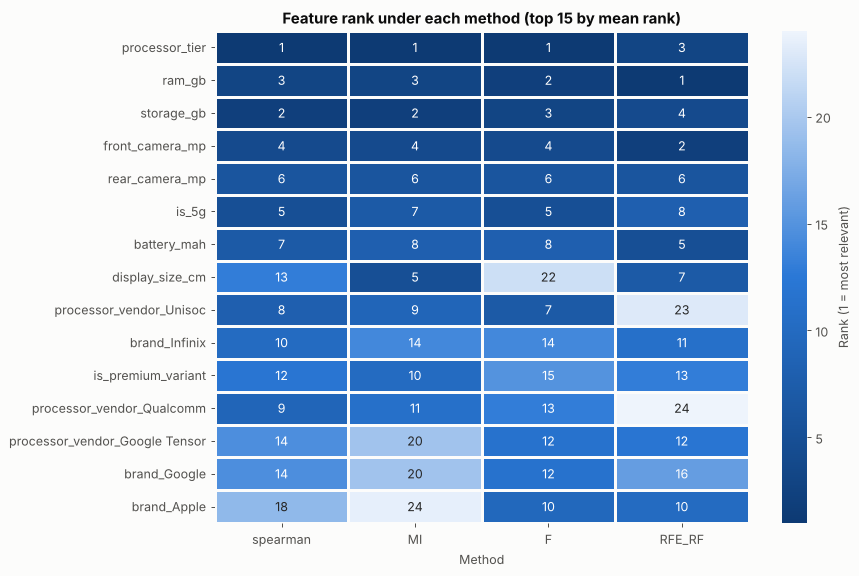

,|spearman|,mutual_info,F_statistic,RFE_rank_RF,mean_rank
processor_tier,0.859,0.780,"1,105.223",3,1.500
ram_gb,0.796,0.723,551.495,1,2.250
storage_gb,0.814,0.740,453.458,4,2.750
front_camera_mp,0.789,0.714,232.210,2,3.500
rear_camera_mp,0.573,0.573,154.649,6,6.000
is_5g,0.597,0.326,154.690,8,6.250
battery_mah,0.458,0.324,75.287,5,7.000
display_size_cm,0.222,0.618,3.906,7,11.750
processor_vendor_Unisoc,0.421,0.164,78.809,23,11.750
brand_Infinix,0.242,0.077,24.739,11,12.250


In [13]:
base = [c for c in X_enc.columns]
relevance = pd.DataFrame({
    "|spearman|": corr["abs_spearman"].reindex(base),
    "mutual_info": mi.reindex(base),
    "F_statistic": stat["F"].reindex(base),
    "RFE_rank_RF": rfe["RFE rank (Random Forest)"].reindex(base),
})
ranks = pd.DataFrame({
    "spearman": relevance["|spearman|"].rank(ascending=False),
    "MI": relevance["mutual_info"].rank(ascending=False),
    "F": relevance["F_statistic"].rank(ascending=False),
    "RFE_RF": relevance["RFE_rank_RF"],
})
relevance["mean_rank"] = ranks.mean(axis=1)
relevance = relevance.sort_values("mean_rank")
relevance.to_csv(PROJECT_ROOT / "reports" / "feature_relevance.csv")

fig, ax = plt.subplots(figsize=(10, 6.5))
r15 = ranks.loc[relevance.index[:15]]
sns.heatmap(r15, annot=True, fmt=".0f", cmap=SEQUENTIAL.reversed(), ax=ax, cbar_kws={"label": "Rank (1 = most relevant)"},
            linewidths=1, linecolor="#fcfcfb")
ax.set(title="Feature rank under each method (top 15 by mean rank)", xlabel="Method", ylabel=""); ax.grid(False)
fig.tight_layout(); save_fig(fig, "fs_rank_agreement")
relevance.head(12).round(3)

**Interpretation.** The methods agree on a stable core: **processor tier, RAM, storage, front camera** take the top
four places under every method, followed by **rear camera, 5G and battery**. Disagreements are informative: display
size is ranked highly only by MI and RF-RFE (the “fingerprint” effect above), Unisoc ranks high on correlation but
low in RFE (its information is already in processor tier), and brand indicators rank low individually but matter as a
group. These rankings are *associations on training data*; Day 6 checks them against what a fitted model actually
relies on.

Written report: `reports/feature_relevance_report.md`.